# LO Peg: reconstructing the relative brightness image

Sixteen real normalized LSD mean-line observations of LO Peg from August 2014 are bound to this task. Rotation turns wavelength into a changing spatial encoding. The reconstruction is a surface field, not a scalar line fit. The original author code is run independently and archived; this notebook executes only cleaned local modules. There is no measured true surface map. **Upstream** means our actual unchanged-source run; **fresh** means calculations executed below, not a paper or cached performance report.

We assume the adopted Roche geometry, fixed local atmosphere and diagonal supplied variances. The angular mesh spacing is a discretization, not a spatial-resolution claim. Invisible or weakly projected regions remain prior dominated. Opposite polarities cancel in circular polarization; brightness and magnetic vector inversions consequently constrain different unknowns.

In [1]:
from pathlib import Path
import os,time,json,hashlib,importlib.util
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd()
if not (ROOT/'src').exists(): ROOT=ROOT.parent
os.chdir(ROOT)
import sys
sys.path.insert(0,str(ROOT))
from src.preprocessing import load_data,reconstruct,prepare,project_spatial,MODE
from src.visualization import surface_panel,residual_panel
data=load_data(); upstream=dict(np.load('notebooks/reference_outputs/upstream.npz',allow_pickle=False))
export=Path(os.environ.get('IMAGING_PRIVATE_FIGURES','output/review_figures'));export.mkdir(parents=True,exist_ok=True)
manifest=[]
def save_group(fig,name,**arrays):
    fig.tight_layout()
    for extension in ['png','svg','pdf']:
        path=export/(name+'.'+extension);fig.savefig(path,dpi=170,bbox_inches='tight')
        manifest.append(dict(file=path.name,sha256=hashlib.sha256(path.read_bytes()).hexdigest(),bytes=path.stat().st_size))
    path=export/(name+'_source.npz');np.savez_compressed(path,**arrays)
    manifest.append(dict(file=path.name,sha256=hashlib.sha256(path.read_bytes()).hexdigest(),bytes=path.stat().st_size))
    plt.show()
started=time.perf_counter();fresh,state=reconstruct(data);runtime=time.perf_counter()-started
fresh_profile=project_spatial(fresh,state)
observed=data['stokes_i' if MODE=='brightness' else 'stokes_v'];sigma=data['sigma_i' if MODE=='brightness' else 'sigma_v']
residual=(fresh_profile-observed)/sigma
baseline=upstream['reconstruction'];delta=fresh-baseline
component_axis=[fresh] if MODE=='brightness' else fresh
reference_axis=[baseline] if MODE=='brightness' else baseline
metrics=[dict(component=i,ncc=float(np.vdot(a,b)/(np.linalg.norm(a)*np.linalg.norm(b))),nrmse=float(np.sqrt(np.mean((a-b)**2))/np.ptp(b)),maximum_absolute_difference=float(np.max(np.abs(a-b)))) for i,(a,b) in enumerate(zip(component_axis,reference_axis))]
print('Fresh full reconstruction seconds:',runtime,'iterations:',len(state.history))
print('Fresh spatial-map reprojection chi-square/sample:',np.mean(residual**2))
display(metrics)
spec=importlib.util.spec_from_file_location('independent_review_judge',ROOT/'evaluation/judge.py');judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
np.savez_compressed('output/reconstruction.npz',reconstruction=fresh[None])
report,status=judge.evaluate('output/reconstruction.npz');assert status==0,report
display(report)
np.savez_compressed('notebooks/reference_outputs/fresh.npz',reconstruction=fresh,profile=fresh_profile,history=state.history,runtime_seconds=runtime)


Fresh full reconstruction seconds: 2.4934167999999772 iterations: 3
Fresh spatial-map reprojection chi-square/sample: 0.9999986664942573


[{'component': 0,
  'ncc': 1.0,
  'nrmse': 0.0,
  'maximum_absolute_difference': 0.0}]

{'status': 'pass',
 'passed': True,
 'metrics': {'brightness_ncc': 1.0,
  'brightness_nrmse': 0.0,
  'observation_chi2_per_sample': 0.9999986664942541},
 'thresholds': {'brightness_ncc': {'comparison': '>=',
   'boundary': 0.999999999},
  'brightness_nrmse': {'comparison': '<=', 'boundary': 1e-07},
  'observation_chi2_per_sample': {'comparison': '<=', 'boundary': 1.002}},
 'errors': []}

## Forward physics and measured fit

With continuum weights $W=A\mu(1-\eta+\eta\mu)g^\beta$, brightness $b$, local intensity $L$, and line-of-sight field $B_{\mathrm{los}}$,

```math
I=\frac{\sum_j W_jb_jL_j}{\sum_j W_jb_j},\qquad
V=\frac{\sum_j W_jb_jB_{j,\mathrm{los}}D_j}{\sum_j W_jb_j},\qquad
D=-4.6686\times10^{-12}\lambda_0^2g_{\mathrm{eff}}\frac{dL}{d\lambda}.
```

Wavelength is in nm, field in gauss, and positive line-of-sight field points toward the observer. The local Humlicek Voigt profile includes Gaussian instrument broadening at resolving power 65000. Scalar line strength is estimated from visible intensity equivalent widths. We retain all sixteen epochs and 89 selected samples. Reduced chi-square below means chi-square divided by sample count, not fitted degrees of freedom. Original error estimates do not establish statistical independence of LSD bins.


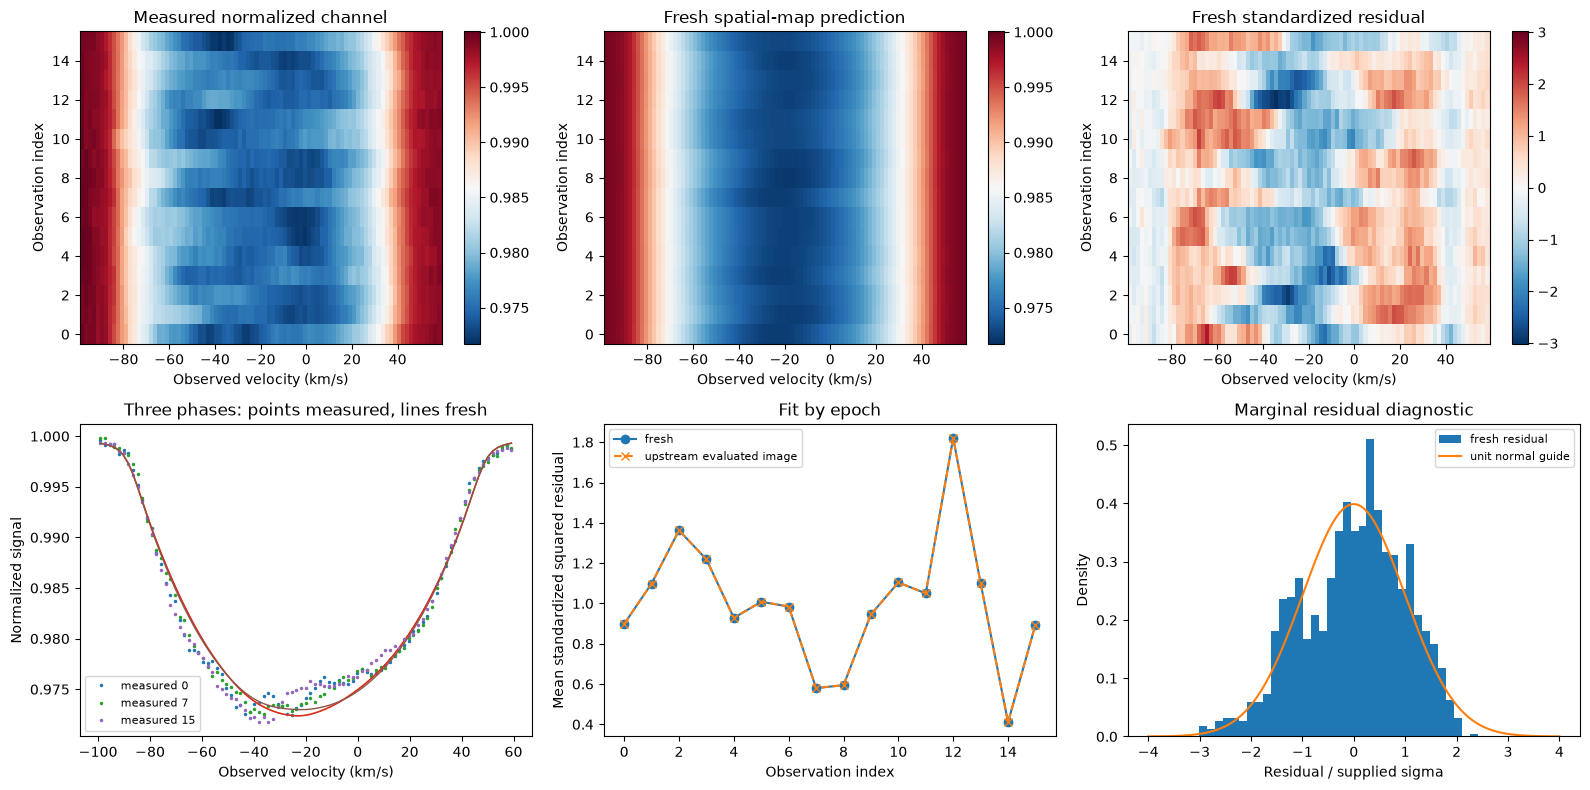

In [2]:
fig,axes=plt.subplots(2,3,figsize=(16,8))
velocity=data['velocity'][0]
for ax,array,title in zip(axes[0],[observed,fresh_profile,residual],['Measured normalized channel','Fresh spatial-map prediction','Fresh standardized residual']):
    im=residual_panel(ax,velocity,array,title)
    if title!='Fresh standardized residual':im.set_clim(min(observed.min(),fresh_profile.min()),max(observed.max(),fresh_profile.max()))
    else:im.set_clim(-np.max(np.abs(residual)),np.max(np.abs(residual)))
    fig.colorbar(im,ax=ax)
for index in [0,7,15]:
    axes[1,0].plot(velocity,observed[index],'.',ms=3,label=f'measured {index}')
    axes[1,0].plot(velocity,fresh_profile[index],'-',lw=1)
axes[1,0].set(xlabel='Observed velocity (km/s)',ylabel='Normalized signal',title='Three phases: points measured, lines fresh');axes[1,0].legend(fontsize=8)
axes[1,1].plot(np.arange(16),np.mean(residual**2,axis=1),'o-',label='fresh')
upres=(upstream['profile']-observed)/sigma
axes[1,1].plot(np.arange(16),np.mean(upres**2,axis=1),'x--',label='upstream evaluated image');axes[1,1].set(xlabel='Observation index',ylabel='Mean standardized squared residual',title='Fit by epoch');axes[1,1].legend(fontsize=8)
axes[1,2].hist(residual.ravel(),bins=35,density=True,label='fresh residual')
z=np.linspace(-4,4,200);axes[1,2].plot(z,np.exp(-z*z/2)/np.sqrt(2*np.pi),label='unit normal guide');axes[1,2].set(xlabel='Residual / supplied sigma',ylabel='Density',title='Marginal residual diagnostic');axes[1,2].legend(fontsize=8)
save_group(fig,'01_observations',velocity=data['velocity'],dates=data['julian_date'],observed=observed,sigma=sigma,fresh_profile=fresh_profile,upstream_profile=upstream['profile'],standardized_residual=residual)


## Spatial reconstruction and observability

The full fitted spatial output is compared with the independently reproduced original result. This is numerical parity, **not** comparison against true starspots or magnetic truth. The observation coverage panel sums normalized projected continuum weights and therefore indicates relative sensitivity, not a reconstructed field. No image alignment is used. The low latitude/hidden hemisphere and polar regions have weaker constraints. Surface area and adopted geometry remain fixed throughout.

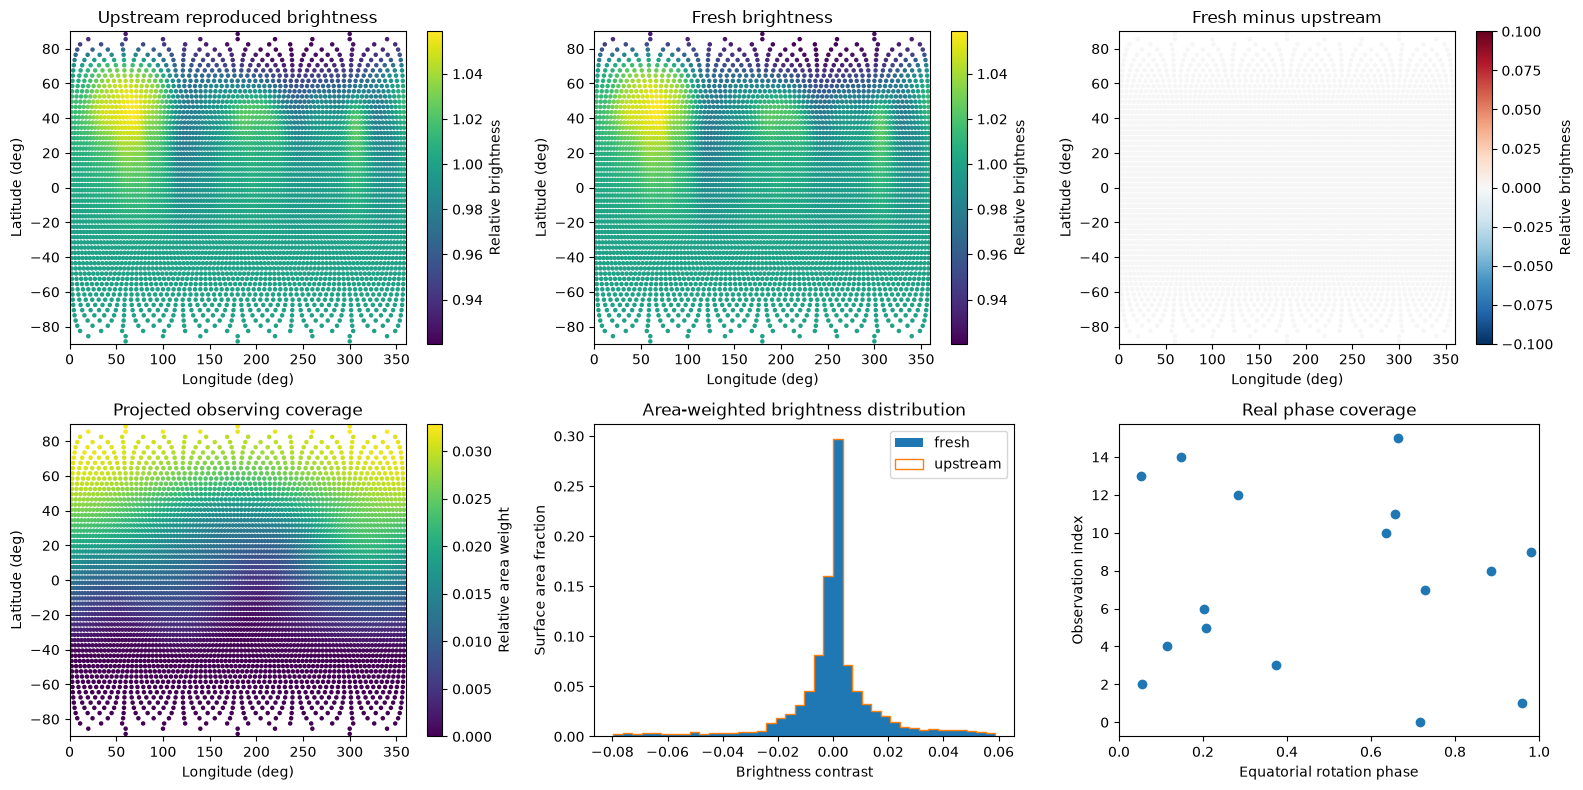

In [3]:
fig,axes=plt.subplots(2,3,figsize=(16,8))
theta=state.grid.clat;phi=state.grid.long
for ax,values,title,cmap,sym in [(axes[0,0],baseline,'Upstream reproduced brightness','viridis',False),(axes[0,1],fresh,'Fresh brightness','viridis',False),(axes[0,2],delta,'Fresh minus upstream','RdBu_r',True)]:
    im=surface_panel(ax,theta,phi,values,title,cmap,sym);fig.colorbar(im,ax=ax,label='Relative brightness')
coverage=np.sum(np.stack([v.projArea*v.visible for v in state.views]),axis=0)
im=surface_panel(axes[1,0],theta,phi,coverage,'Projected observing coverage');fig.colorbar(im,ax=axes[1,0],label='Relative area weight')
axes[1,1].hist(fresh-1,bins=40,weights=state.grid.area/state.grid.area.sum(),label='fresh');axes[1,1].hist(baseline-1,bins=40,weights=state.grid.area/state.grid.area.sum(),histtype='step',label='upstream');axes[1,1].set(xlabel='Brightness contrast',ylabel='Surface area fraction',title='Area-weighted brightness distribution');axes[1,1].legend()
phase=((data['julian_date']-2456892.015)/.4232)%1
axes[1,2].plot(phase,np.arange(16),'o');axes[1,2].set(xlabel='Equatorial rotation phase',ylabel='Observation index',xlim=(0,1),title='Real phase coverage')
save_group(fig,'02_spatial',colatitude=theta,longitude=phi,radius=state.grid.radius,area=state.grid.area,fresh=fresh,upstream=baseline,difference=delta,coverage=coverage,phase=phase)


## Convergence and actual sensitivity reconstructions

The weighted misfit is $C=\sum_k[(F_k-d_k)/\sigma_k]^2$, where $d$ is the measured channel, $F$ the predicted channel, and $\sigma$ the supplied marginal standard deviation. The local implementation uses ten search directions from the entropy and misfit gradients, entropy-metric whitening, projected curvature diagonalization and the published two-multiplier step control. Brightness entropy favors the unit photosphere with cell-area weights. Signed magnetic entropy favors zero harmonic coefficients with degree weights. Each iteration records the evaluated image and proposes the next update; stopping requires $C/N\le1.001$ and Test below $10^{-4}$, with $N=1424$ measured samples and a 20-iteration cap.

Targets 0.8, 1.0 and 1.2 below are fresh independent runs. They expose how different fit assumptions change the inferred spatial image. They are sensitivity analyses, not additional measurements or demonstrations of true surface accuracy. The magnetic target 0.8 exhausts the 20-step budget without satisfying both convergence tests; its actual fit and budget limit are reported. The standard target 1.0 converges. The original final brightness proposal aliases its image, while its archived final spectrum belongs to the previous evaluated iterate. We explicitly reproject the returned spatial output for fresh residuals.


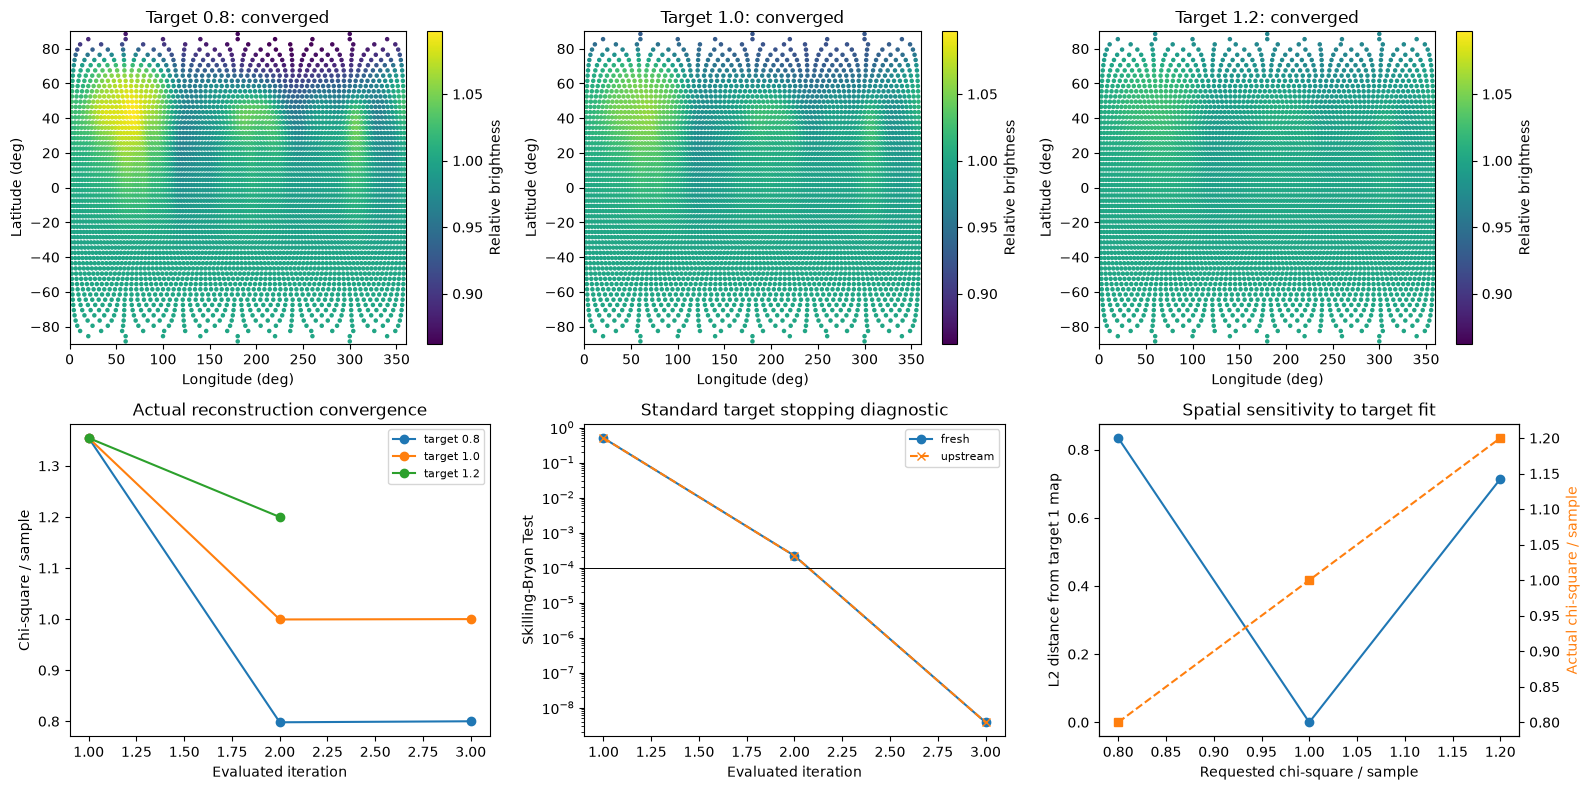

[{'target': 0.8,
  'actual_chi2': 0.800000000000256,
  'iterations': 3,
  'seconds': 3.05824389999907},
 {'target': 1.0,
  'actual_chi2': 0.9999986664942573,
  'iterations': 3,
  'seconds': 3.123333299998194},
 {'target': 1.2,
  'actual_chi2': 1.1999993794270583,
  'iterations': 2,
  'seconds': 2.6753083000003244}]

1799

In [4]:
targets=np.array([.8,1.,1.2]);sensitivity=[];sensitivity_histories=[];sensitivity_chi=[];sensitivity_seconds=[]
for target in targets:
    start=time.perf_counter();image,current=reconstruct(data,target=float(target));prediction=project_spatial(image,current)
    sensitivity_seconds.append(time.perf_counter()-start);sensitivity.append(image);sensitivity_histories.append(current.history)
    sensitivity_chi.append(float(np.mean(((prediction-observed)/sigma)**2)))
sensitivity=np.array(sensitivity);sensitivity_chi=np.array(sensitivity_chi)
fig,axes=plt.subplots(2,3,figsize=(16,8))
for ax,target,image in zip(axes[0],targets,sensitivity):
    values=image if MODE=='brightness' else np.linalg.norm(image,axis=0)
    index=int(np.flatnonzero(targets==target)[0]);history=sensitivity_histories[index]
    converged=history[-1,1]<=target*observed.size*1.001 and history[-1,2]<1e-4
    im=surface_panel(ax,theta,phi,values,f'Target {target:.1f}: '+('converged' if converged else '20-step budget reached'))
    all_values=sensitivity if MODE=='brightness' else np.linalg.norm(sensitivity,axis=1)
    im.set_clim(np.min(all_values),np.max(all_values))
    fig.colorbar(im,ax=ax,label='Relative brightness' if MODE=='brightness' else 'G')
for history,target in zip(sensitivity_histories,targets):
    axes[1,0].plot(np.arange(1,len(history)+1),history[:,1]/observed.size,'o-',label=f'target {target:.1f}')
axes[1,0].set(xlabel='Evaluated iteration',ylabel='Chi-square / sample',title='Actual reconstruction convergence');axes[1,0].legend(fontsize=8)
axes[1,1].semilogy(np.arange(1,len(state.history)+1),np.maximum(state.history[:,2],1e-18),'o-',label='fresh')
axes[1,1].semilogy(np.arange(1,len(upstream['history'])+1),np.maximum(upstream['history'][:,2],1e-18),'x--',label='upstream');axes[1,1].axhline(1e-4,color='k',lw=.7);axes[1,1].set(xlabel='Evaluated iteration',ylabel='Skilling-Bryan Test',title='Standard target stopping diagnostic');axes[1,1].legend(fontsize=8)
spread=np.sqrt(np.sum((sensitivity-sensitivity[1])**2,axis=tuple(range(1,sensitivity.ndim))))
axes[1,2].plot(targets,spread,'o-',label='Spatial L2 change')
axes[1,2].set(xlabel='Requested chi-square / sample',ylabel='L2 distance from target 1 map',title='Spatial sensitivity to target fit')
second=axes[1,2].twinx();second.plot(targets,sensitivity_chi,'s--',color='tab:orange',label='actual fit');second.set_ylabel('Actual chi-square / sample',color='tab:orange')
save_group(fig,'03_convergence_sensitivity',targets=targets,sensitivity=sensitivity,actual_chi2=sensitivity_chi,spatial_l2_change=spread,standard_history=state.history,upstream_history=upstream['history'],sensitivity_seconds=np.array(sensitivity_seconds),**{f'history_{i}':h for i,h in enumerate(sensitivity_histories)})
display([dict(target=float(t),actual_chi2=float(c),iterations=len(h),seconds=float(s)) for t,c,h,s in zip(targets,sensitivity_chi,sensitivity_histories,sensitivity_seconds)])
(export/'manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')


## Interpretation

All displayed reconstructions and target sensitivities were computed in this execution. Fresh cleaned results satisfy the independent spatial and observation contracts. The source comparison validates extraction of geometry, line profile physics and entropy updates; it does not establish the astrophysical truth of the relative brightness image. The adopted atmosphere, inclination, differential rotation and marginal errors are conditional assumptions. Resolution is limited by rotational encoding, intrinsic/instrument line width, viewing coverage and cancellation, with an unconstrained or weakly constrained southern region. The 4584-cell mesh supplies output sampling rather than 4584 independent measurements.

See the self-contained README for units/acquisition and `plan/approach.md` for the implemented equations, proposal convention and stopping rules. Original and fresh measurements remain separately identified. Source revision, licenses, exact observations, backend, commands and numerical differences are recorded in `test/validation.md`.